## Q1. Write a query to list the top 10 genres with the highest number of tracks. (Show in bar plot)

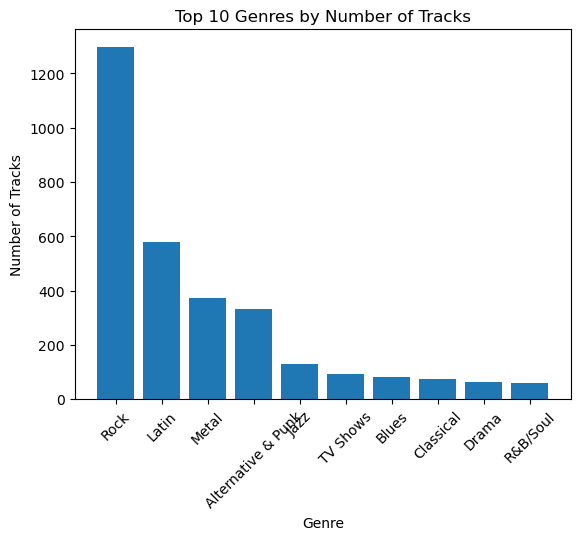

In [1]:
import pandas as pd
import sqlite3 as sql
conn = sql.connect("chinook.db")

def sql_query(q):
    return pd.read_sql_query(q, conn)
q="""select count(t.track_id) as track_count,g.name
from genre g inner join
track t
on
g.genre_id=t.genre_id
GROUP BY g.genre_id, g.name
order by track_count desc limit 10




"""    
sql_query(q)
import matplotlib.pyplot as plt

df = sql_query(q)

plt.bar(df["name"], df["track_count"])

plt.xlabel("Genre")
plt.ylabel("Number of Tracks")
plt.title("Top 10 Genres by Number of Tracks")

plt.xticks(rotation=45)
plt.show()

## Q2. Write a query to list the top 10 albums that contain the most tracks.

In [2]:
q = """
SELECT al.title, al.album_id, COUNT(t.track_id) AS track_count
FROM album al
INNER JOIN track t
ON al.album_id = t.album_id
GROUP BY al.album_id, al.title
ORDER BY track_count DESC
LIMIT 10
"""

sql_query(q)

,title,album_id,track_count
0,Greatest Hits,141,57
1,Minha Historia,23,34
2,Unplugged,73,30
3,"Lost, Season 3",229,26
4,"Lost, Season 1",230,25
5,"The Office, Season 3",251,25
6,My Way: The Best Of Frank Sinatra [Disc 1],83,24
7,"Lost, Season 2",231,24
8,"Battlestar Galactica (Classic), Season 1",253,24
9,Afrociberdelia,24,23


## Q3. Write a query to find the top 10 customers who spent the most money.

In [3]:
q="""select c.first_name,i.total from customer c
inner join invoice i
on
c.customer_id=i.customer_id
order by i.total desc limit 10

"""
sql_query(q)

,first_name,total
0,Wyatt,23.76
1,François,19.80
2,Aaron,19.80
3,Robert,19.80
4,František,19.80
5,Heather,18.81
6,Richard,17.82
7,Mark,17.82
8,Ladislav,17.82
9,Camille,17.82


## Q4. Write a query to find the top 5 artists who generated the highest revenue from track sales.

In [4]:
q="""select ar.name,sum(il.unit_price * il.quantity) as revenue from artist ar
inner join album a on
ar.artist_id=a.album_id
inner join track t on
a.album_id=t.album_id
inner join invoice_line il on
t.track_id=il.track_id
group by ar.name,ar.artist_id
order by revenue desc limit 5



"""
sql_query(q)

,name,revenue
0,Pink Floyd,185.13
1,Guns N' Roses,95.04
2,"Richard Marlow & The Choir of Trinity College,...",92.07
3,Peter Tosh,89.10
4,Academy of St. Martin in the Fields & Sir Nevi...,82.17


## Q5. Countries by Average Revenue per Invoice

In [5]:
q = """
SELECT billing_country AS country,
       AVG(total) AS average_revenue
FROM invoice
GROUP BY billing_country
ORDER BY average_revenue DESC
"""

sql_query(q)

,country,average_revenue
0,Czech Republic,9.108000
1,Spain,8.910000
2,Ireland,8.833846
3,United Kingdom,8.768571
4,India,8.721429
5,Belgium,8.627143
6,Germany,8.161463
7,Australia,8.118000
8,Norway,8.030000
9,USA,7.942672


## Q6. Write a query to find the media type with number of tracks.


In [9]:

q = """
SELECT m.name, COUNT(t.track_id) AS number_of_tracks
FROM media_type m
INNER JOIN track t
    ON m.media_type_id = t.media_type_id
GROUP BY m.name
ORDER BY number_of_tracks DESC;
"""
sql_query(q)

,name,number_of_tracks
0,MPEG audio file,3034
1,Protected AAC audio file,237
2,Protected MPEG-4 video file,214
3,AAC audio file,11
4,Purchased AAC audio file,7


## Q7. Which artists have released tracks in more than one genre?

In [13]:
q = """
SELECT ar.name
FROM artist ar
JOIN album al ON ar.artist_id = al.artist_id
JOIN track t ON al.album_id = t.album_id
JOIN genre g ON t.genre_id = g.genre_id
GROUP BY ar.artist_id, ar.name
HAVING COUNT(DISTINCT g.genre_id) > 1;
"""
sql_query(q)



,name
0,Antônio Carlos Jobim
1,Audioslave
2,Various Artists
3,Gilberto Gil
4,Eric Clapton
5,Faith No More
6,Foo Fighters
7,Guns N' Roses
8,Iron Maiden
9,Jamiroquai


## Q8. Write a query to list the top 10 longest tracks by duration.

In [14]:
q="""SELECT name, milliseconds
FROM track order by milliseconds desc limit 10


"""
sql_query(q)

,name,milliseconds
0,Occupation / Precipice,5286953
1,Through a Looking Glass,5088838
2,"Greetings from Earth, Pt. 1",2960293
3,The Man With Nine Lives,2956998
4,"Battlestar Galactica, Pt. 2",2956081
5,"Battlestar Galactica, Pt. 1",2952702
6,Murder On the Rising Star,2935894
7,"Battlestar Galactica, Pt. 3",2927802
8,Take the Celestra,2927677
9,Fire In Space,2926593


## Q9. Top 5 Revenue Share percentage by Artist (Pie Chart)

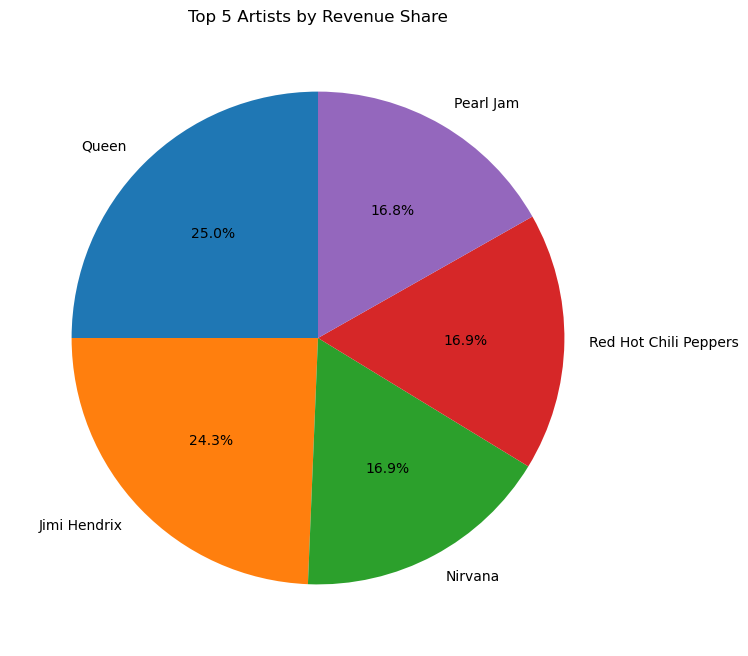

In [17]:
q = """
SELECT ar.name AS artist,
       SUM(il.unit_price * il.quantity) AS revenue
FROM artist ar
JOIN album al ON ar.artist_id = al.artist_id
JOIN track t ON al.album_id = t.album_id
JOIN invoice_line il ON t.track_id = il.track_id
GROUP BY ar.artist_id, ar.name
ORDER BY revenue DESC
LIMIT 5;
"""

df = sql_query(q)
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

plt.pie(
    df["revenue"],
    labels=df["artist"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Top 5 Artists by Revenue Share")
plt.show()

## Q10. Revenue by Genre (Rock, Latin, Metal) in Each Country (Stacked Column Chart)